# **Week 6 Lab** <br/> Practical SIFT Application
## Task 4
In the code (SIFTImage_Match.ipynb), ensure proper naming of Left and Right Images.

Run/Execute the program, view output results and comment on
the detected keypoints.
Note Number of keypoints detected


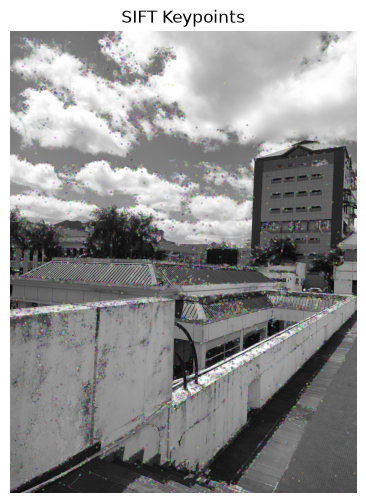

Number of keypoints detected: 8162
Shape of descriptors: (8162, 128)
Number of good matches: 54


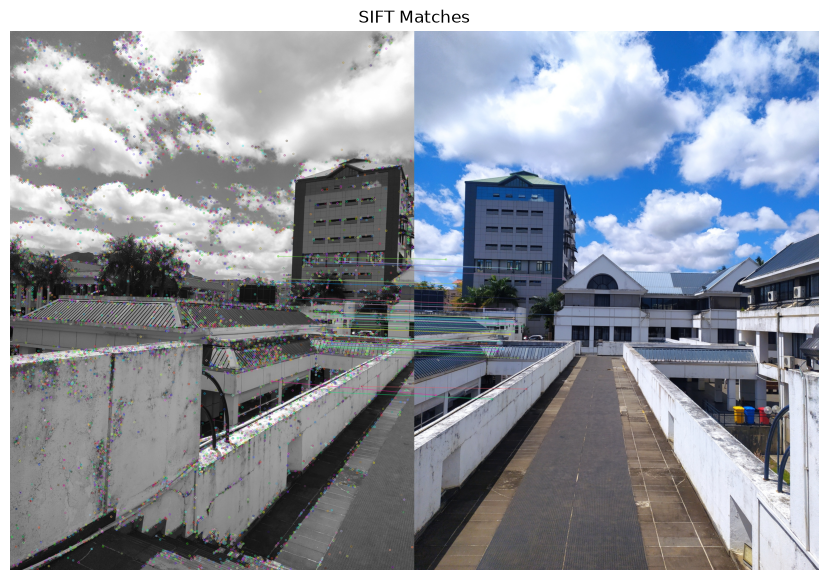

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the Right image
img = cv2.imread('Images/BridgeLeft1.jpg')  # Replace 'image.jpg' with your image file
# Convert the image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# Create SIFT object
sift = cv2.SIFT_create()
# Detect keypoints and compute descriptors
keypoints, descriptors = sift.detectAndCompute(gray, None)
# Draw keypoints on the image (optional)
img_with_keypoints = cv2.drawKeypoints(gray, keypoints, img)
# Display the image with keypoints using Matplotlib
# cv2.imshow('SIFT Keypoints', img_with_keypoints)
# cv2.waitKey(0)
# cv2.destroyAllWindows()
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img_with_keypoints, cv2.COLOR_BGR2RGB))
plt.title('SIFT Keypoints')
plt.axis('off')
plt.show()
# Print the number of keypoints detected
print("Number of keypoints detected:", len(keypoints))
# Print the shape of the descriptors
print("Shape of descriptors:", descriptors.shape) # Should be (number of keypoints, 128)
# Example of matching with brute force matcher.

# Load a second image Left Part
img2 = cv2.imread('Images/BridgeRight1.jpg') # Replace 'image2.jpg' with your second image file
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
keypoints2, descriptors2 = sift.detectAndCompute(gray2, None)
# Create a brute-force matcher
bf = cv2.BFMatcher()
matches = bf.knnMatch(descriptors, descriptors2, k=2) # k=2 means find the best 2 matches
# Apply ratio test to filter good matches (Lowe's ratio test)
good_matches = []
for m,n in matches:
    if m.distance < 0.25*n.distance:  #Adjust the 0.25 threshold to tune the matching performance
        good_matches.append([m])
print("Number of good matches:", len(good_matches))
# Draw the good matches
img_matches = cv2.drawMatchesKnn(img,keypoints,img2,keypoints2,good_matches,None,flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
# Display the matches using Matplotlib
# cv2.imshow("Matches", img_matches)
# cv2.waitKey(0)
# cv2.destroyAllWindows()
plt.figure(figsize=(14, 7))
plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
plt.title('SIFT Matches')
plt.axis('off')
plt.show()

### Observations

| Right image | Left image | Threshold | Right keypoints | Left keypoints | Good matches |
|---|---|---:|---:|---:|---:|
| TowerRight.jpg | TowerLeft.jpg | 0.25 | 1567 | 1321 | 462 |
| TowerRight.jpg | TowerLeft.jpg | 0.5 | 1567 | 1321 | 541 |
| TowerRight.jpg | TowerLeft.jpg | 0.75 | 1567 | 1321 | 618 |
| CafetariaRight.png | CafetariaLeft.png | 0.25 | 7300 | 7661 | 2088 |
| CafetariaRight.png | CafetariaLeft.png | 0.5 | 7300 | 7661 | 2125 |
| CafetariaRight.png | CafetariaLeft.png | 0.75 | 7300 | 7661 | 2214 |
| ZurichImageA.jpg | ZurichImageB.jpg | 0.25 | 1551 | 1588 | 23 |
| ZurichImageA.jpg | ZurichImageB.jpg | 0.5 | 1551 | 1588 | 74 |
| ZurichImageA.jpg | ZurichImageB.jpg | 0.75 | 1551 | 1588 | 157 |
| AgriBuildingRight.png | AgriBuildingLeft.png | 0.25 | 3240 | 2374 | 844 |
| AgriBuildingRight.png | AgriBuildingLeft.png | 0.5 | 3240 | 2374 | 879 |
| AgriBuildingRight.png | AgriBuildingLeft.png | 0.75 | 3240 | 2374 | 965 |
| BridgeRight2.jpg | BridgeLeft2.jpg | 0.25 | 13014 | 12533 | 21 |
| BridgeRight2.jpg | BridgeLeft2.jpg | 0.5 | 13014 | 12533 | 376 |
| BridgeRight2.jpg | BridgeLeft2.jpg | 0.75 | 13014 | 12533 | 1056 |
| BridgeRight1.jpg | BridgeLeft1.jpg | 0.25 | 6751 | 8142 | 54 |
| BridgeRight1.jpg | BridgeLeft1.jpg | 0.5 | 6751 | 8142 | 336 |
| BridgeRight1.jpg | BridgeLeft1.jpg | 0.75 | 6751 | 8142 | 774 |

- The number of detected keypoints is independent of the matching threshold because SIFT detection runs once per image. Cafetaria and Bridge 2 produce the most keypoints, while Tower and Zurich produce fewer.
- Good matches increase for every pair as the threshold rises from 0.25 to 0.75 because the Lowe ratio test becomes less strict.
- Tower, Cafetaria, and AgriBuilding have many good matches at all thresholds, indicating strong overlap or distinctive shared features.
- Zurich and both Bridge pairs are more sensitive to the threshold. In particular, Zurich has very few matches at 0.25, and Bridge 2 rises sharply from 21 to 1056 matches.

Thank you for watching!